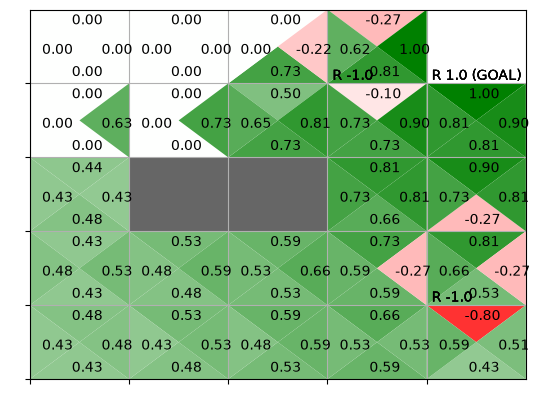

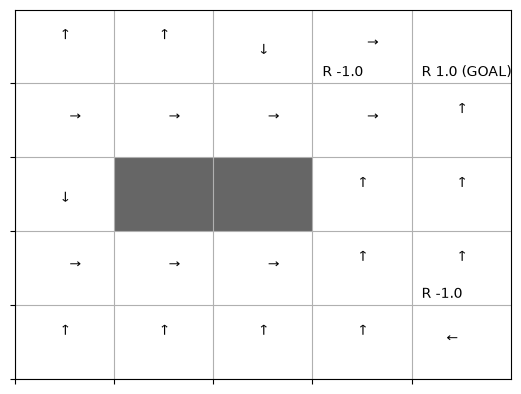

In [1]:
import os, sys; 
sys.path.append(os.pardir)  # for importing the parent dirs
from collections import defaultdict
import numpy as np
from common.gridworld import GridWorld
from common.utils import greedy_probs


class QLearningAgent:
    def __init__(self):
        self.gamma = 0.9
        self.alpha = 0.8
        self.epsilon = 0.1
        self.action_size = 4

        random_actions = {0: 0.25, 1: 0.25, 2: 0.25, 3: 0.25}
        self.pi = defaultdict(lambda: random_actions)
        self.b = defaultdict(lambda: random_actions)  # 행동 정책
        self.Q = defaultdict(lambda: 0)

    def get_action(self, state):
        action_probs = self.b[state]  # 행동 정책에서 가져옴
        actions = list(action_probs.keys())
        probs = list(action_probs.values())
        return np.random.choice(actions, p=probs)

    def update(self, state, action, reward, next_state, done):
        if done:  # 목표에 도달
            next_q_max = 0
        else:     # 그 외에는 다음 상태에서 Q 함수의 최댓값 계산
            next_qs = [self.Q[next_state, a] for a in range(self.action_size)]
            next_q_max = max(next_qs)

        # Q 함수 갱신
        target = reward + self.gamma * next_q_max
        self.Q[state, action] += (target - self.Q[state, action]) * self.alpha

        # 행동 정책과 대상 정책 갱신
        self.pi[state] = greedy_probs(self.Q, state, epsilon=0)
        self.b[state] = greedy_probs(self.Q, state, self.epsilon)


env = GridWorld()
agent = QLearningAgent()

episodes = 10000
for episode in range(episodes):
    state = env.reset()

    while True:
        action = agent.get_action(state)
        next_state, reward, done = env.step(action)

        agent.update(state, action, reward, next_state, done)
        if done:
            break
        state = next_state

# [그림 6-15] Q 러닝으로 얻은 Q 함수와 정책
env.render_q(agent.Q)